In [1]:
import pandas as pd
import json
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("Biblioteker lastet inn!")

Biblioteker lastet inn!


In [2]:
# Last inn klassifiserte data
with open("../data/klassifisert.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)
print(f"Lastet {len(df)} klassifiserte diagnoser")
df.head()

Lastet 5 klassifiserte diagnoser


,id,diagnosis,diagnosis_clean,kategori
0,J0001,Hysteria med kramper,hysteria med kramper,4. Epilepsi-relatert
1,J0002,"ex constitutione, svak konstitusjon","ex constitutione, svak konstitusjon",3. Ex constitutione
2,J0003,Hysterisk personlighet,hysterisk personlighet,2. Hysterisk personlighet
3,J0005,Epilepsi med hysteriske trekk,epilepsi med hysteriske trekk,4. Epilepsi-relatert
4,J0007,ukjent,ukjent,5. Annet


In [5]:
import numpy as np

# Ta 50 tilfeldige poster
df_sample = df.sample(n=min(50, len(df)), random_state=42).copy()

# Legg til en tom kolonne for din manuelle vurdering
df_sample["fasit"] = ""

# Lagre som ExCel - enkel å åpne i Excel
df_sample[["id", "diagnosis", "kategori", "fasit"]].to_excel(
    "../data/gullstandard.xlsx", 
    index=False
)
print(f"Lagret {len(df_sample)} poster til gullstandard.xlsx")
print("Åpne filen i Excel, fyll inn kolonne 'fasit' med tall 1-5, lagre og kom tilbake!")

Lagret 5 poster til gullstandard.xlsx
Åpne filen i Excel, fyll inn kolonne 'fasit' med tall 1-5, lagre og kom tilbake!


In [6]:
# Last inn din manuelle vurdering
df_fasit = pd.read_excel("../data/gullstandard.xlsx")

# Fjern rader uten fasit
df_fasit = df_fasit[df_fasit["fasit"].notna()]
df_fasit = df_fasit[df_fasit["fasit"] != ""]

print(f"Antall manuelt vurderte: {len(df_fasit)}")
print(f"\nGemma vs. din vurdering:")
df_fasit[["id", "diagnosis", "kategori", "fasit"]]

Antall manuelt vurderte: 5

Gemma vs. din vurdering:


,id,diagnosis,kategori,fasit
0,J0002,"ex constitutione, svak konstitusjon",3. Ex constitutione,3
1,J0007,ukjent,5. Annet,5
2,J0003,Hysterisk personlighet,2. Hysterisk personlighet,2
3,J0001,Hysteria med kramper,4. Epilepsi-relatert,4
4,J0005,Epilepsi med hysteriske trekk,4. Epilepsi-relatert,4


In [8]:
# Hent bare nummeret fra Gemma sin kategori
df_fasit["kategori_nr"] = df_fasit["kategori"].str[0]
df_fasit["fasit_str"] = df_fasit["fasit"].astype(str).str[0]

riktige = (df_fasit["kategori_nr"] == df_fasit["fasit_str"]).sum()
totalt = len(df_fasit)
nøyaktighet = riktige / totalt * 100

print(f"Riktige: {riktige} av {totalt}")
print(f"Nøyaktighet: {nøyaktighet:.1f}%")

for _, rad in df_fasit.iterrows():
    riktig = "✅" if rad["kategori_nr"] == rad["fasit_str"] else "❌"
    print(f"  {riktig} {rad['id']}: Gemma={rad['kategori']} | Fasit={rad['fasit']}")

Riktige: 5 av 5
Nøyaktighet: 100.0%
  ✅ J0002: Gemma=3. Ex constitutione | Fasit=3
  ✅ J0007: Gemma=5. Annet | Fasit=5
  ✅ J0003: Gemma=2. Hysterisk personlighet | Fasit=2
  ✅ J0001: Gemma=4. Epilepsi-relatert | Fasit=4
  ✅ J0005: Gemma=4. Epilepsi-relatert | Fasit=4


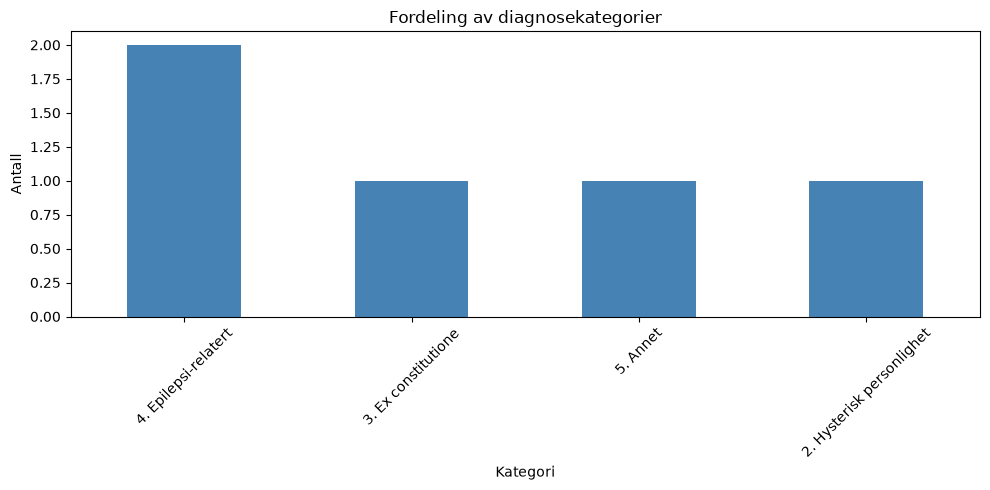

Plot lagret!


In [9]:
# Tell opp kategorier
kategori_telling = df_fasit["kategori"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
kategori_telling.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Fordeling av diagnosekategorier")
ax.set_xlabel("Kategori")
ax.set_ylabel("Antall")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("../results/kategori_fordeling.png", dpi=150)
plt.show()

print("Plot lagret!")

In [11]:
from sklearn.metrics import classification_report
import pandas as pd

# Lag rapport som dictionary
rapport = classification_report(
    df_fasit["fasit_str"], 
    df_fasit["kategori_nr"],
    zero_division=0,
    output_dict=True
)

# Gjør om til pen tabell
df_rapport = pd.DataFrame(rapport).T
df_rapport = df_rapport.round(2)

# Bytt ut tallkoder med kategorinavn
kategorinavn = {
    "1": "Hysteria",
    "2": "Hysterisk personlighet",
    "3": "Ex constitutione",
    "4": "Epilepsi-relatert",
    "5": "Annet",
    "accuracy": "Nøyaktighet",
    "macro avg": "Makro gjennomsnitt",
    "weighted avg": "Vektet gjennomsnitt"
}
df_rapport.index = df_rapport.index.map(lambda x: kategorinavn.get(x, x))

# Vis tabellen
df_rapport[["precision", "recall", "f1-score", "support"]].style\
    .background_gradient(subset=["precision", "recall", "f1-score"], cmap="Greens")\
    .format({"precision": "{:.2f}", "recall": "{:.2f}", 
             "f1-score": "{:.2f}", "support": "{:.0f}"})

,precision,recall,f1-score,support
Hysterisk personlighet,1.00,1.00,1.00,1
Ex constitutione,1.00,1.00,1.00,1
Epilepsi-relatert,1.00,1.00,1.00,2
Annet,1.00,1.00,1.00,1
Nøyaktighet,1.00,1.00,1.00,1
Makro gjennomsnitt,1.00,1.00,1.00,5
Vektet gjennomsnitt,1.00,1.00,1.00,5
